In [1]:
import os
import glob
import zipfile
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression, SGDRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:

import pandas as pd
from google.colab import files
import os

# Upload your salary dataset
uploaded = files.upload()

# Automatically find the uploaded CSV file
csv_files = [name for name in uploaded.keys() if name.endswith(".csv")]

if not csv_files:
    raise FileNotFoundError("Please upload your Salary_dataset.csv file.")

filename = csv_files[0]

# Load the dataset
df = pd.read_csv(filename)

# Display the dataset
print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())


Saving Salary_dataset.csv to Salary_dataset (4).csv
Dataset loaded successfully!
Shape: (30, 3)


,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0



Column names:
['Unnamed: 0', 'YearsExperience', 'Salary']


In [7]:
zip_path = "/content/salary-dataset-simple-linear-regression.zip"

if not os.path.exists(zip_path):
    subprocess.run(
        [
            "kaggle", "datasets", "download",
            "-d", "abhishek14398/salary-dataset-simple-linear-regression",
            "-p", "/content"
        ],
        check=True
    )

extract_folder = "/content/data"
os.makedirs(extract_folder, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

csv_files = glob.glob(
    os.path.join(extract_folder, "**", "*.csv"),
    recursive=True
)

if not csv_files:
    raise FileNotFoundError("No CSV file was found inside the dataset ZIP.")

csv_path = csv_files[0]
df = pd.read_csv(csv_path)

print("CSV file:", csv_path)
print("Dataset downloaded and loaded!")
display(df.head())

CSV file: /content/data/Salary_dataset.csv
Dataset downloaded and loaded!


,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [8]:
print("First five rows:")
display(df.head())

print("\nLast five rows:")
display(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

First five rows:


,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0



Last five rows:


,Unnamed: 0,YearsExperience,Salary
25,25,9.1,105583.0
26,26,9.6,116970.0
27,27,9.7,112636.0
28,28,10.4,122392.0
29,29,10.6,121873.0



Dataset shape:
(30, 3)

Column names:
['Unnamed: 0', 'YearsExperience', 'Salary']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes

Statistical summary:


,Unnamed: 0,YearsExperience,Salary
count,30.000000,30.000000,30.000000
mean,14.500000,5.413333,76004.000000
std,8.803408,2.837888,27414.429785
min,0.000000,1.200000,37732.000000
25%,7.250000,3.300000,56721.750000
50%,14.500000,4.800000,65238.000000
75%,21.750000,7.800000,100545.750000
max,29.000000,10.600000,122392.000000



Missing values:


,0
Unnamed: 0,0
YearsExperience,0
Salary,0



Duplicate rows: 0


In [9]:
# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Remove the index column because it is not a useful predictor
if "Unnamed: 0" in df.columns:
    df.drop(columns=["Unnamed: 0"], inplace=True)

# Ensure both columns are numeric
df["YearsExperience"] = pd.to_numeric(
    df["YearsExperience"], errors="coerce"
)

df["Salary"] = pd.to_numeric(
    df["Salary"], errors="coerce"
)

# Remove rows with missing values in the required columns
df.dropna(
    subset=["YearsExperience", "Salary"],
    inplace=True
)

df.reset_index(drop=True, inplace=True)

print("Cleaned dataset shape:", df.shape)
display(df.head())

print("\nMissing values after cleaning:")
display(df.isnull().sum())

Cleaned dataset shape: (30, 2)


,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0



Missing values after cleaning:


,0
YearsExperience,0
Salary,0


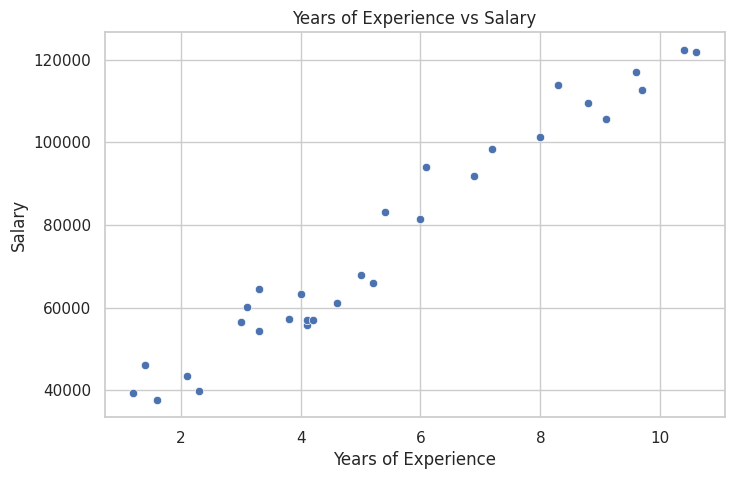

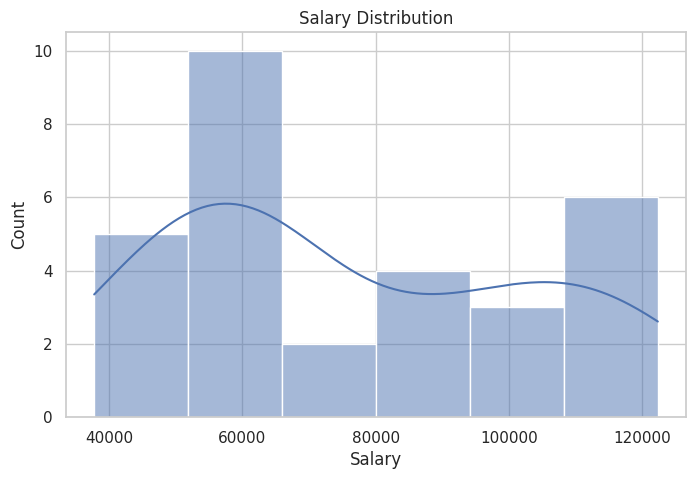

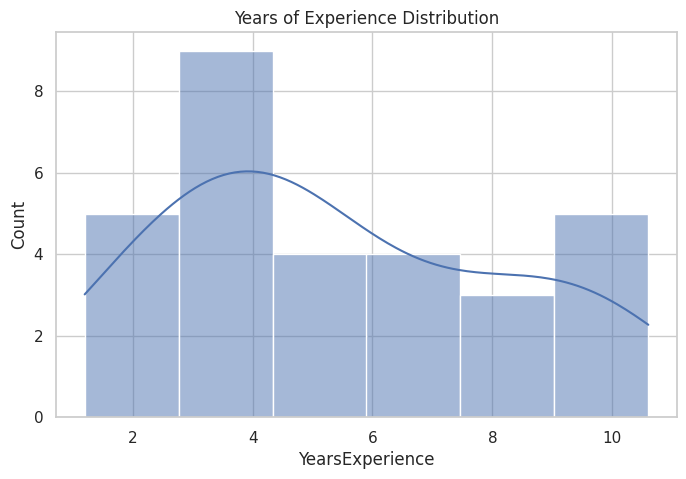

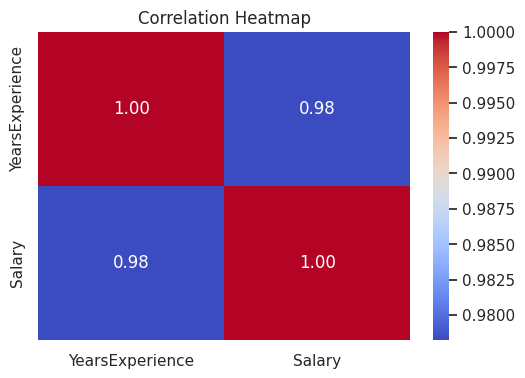

In [10]:
# Experience vs salary
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="YearsExperience",
    y="Salary"
)
plt.title("Years of Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.show()

# Salary distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Salary"], kde=True)
plt.title("Salary Distribution")
plt.show()

# Experience distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["YearsExperience"], kde=True)
plt.title("Years of Experience Distribution")
plt.show()

# Correlation heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(
    df[["YearsExperience", "Salary"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

In [11]:
# Create a squared experience feature
df["Experience_Squared"] = df["YearsExperience"] ** 2

print("Dataset after feature engineering:")
display(df.head())

print("Features:", ["YearsExperience", "Experience_Squared"])
print("Target:", "Salary")

Dataset after feature engineering:


,YearsExperience,Salary,Experience_Squared
0,1.2,39344.0,1.44
1,1.4,46206.0,1.96
2,1.6,37732.0,2.56
3,2.1,43526.0,4.41
4,2.3,39892.0,5.29


Features: ['YearsExperience', 'Experience_Squared']
Target: Salary


In [12]:
X = df[["YearsExperience"]]
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 24
Testing rows: 6


In [13]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Model trained successfully!")
print("Slope:", linear_model.coef_[0])
print("Intercept:", linear_model.intercept_)

Model trained successfully!
Slope: 9423.815323030976
Intercept: 24380.201479473704


In [14]:
y_pred = linear_model.predict(X_test)

results = pd.DataFrame({
    "YearsExperience": X_test["YearsExperience"].values,
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred
})

display(results)

,YearsExperience,Actual Salary,Predicted Salary
0,9.7,112636.0,115791.210113
1,5.0,67939.0,71499.278095
2,8.3,113813.0,102597.868661
3,5.4,83089.0,75268.804224
4,3.3,64446.0,55478.792045
5,3.8,57190.0,60190.699707


In [15]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

MAE: 6286.45
MSE: 49830096.86
RMSE: 7059.04
R² Score: 0.9024


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


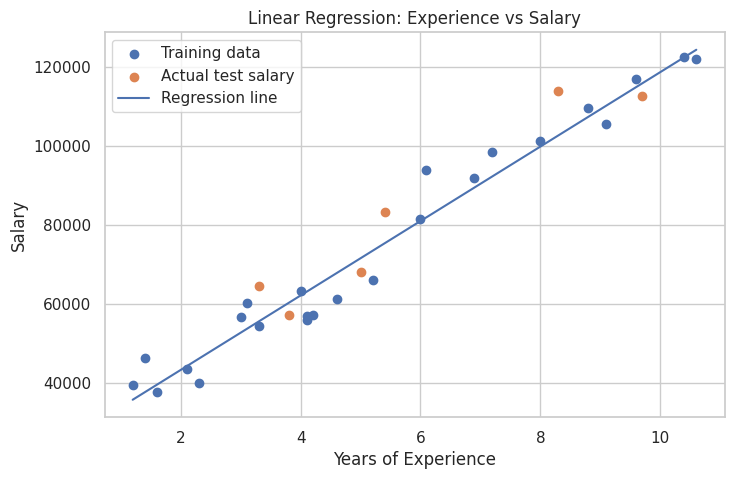

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_train["YearsExperience"],
    y_train,
    label="Training data"
)

plt.scatter(
    X_test["YearsExperience"],
    y_test,
    label="Actual test salary"
)

sorted_indices = np.argsort(
    df["YearsExperience"].values
)

x_line = df["YearsExperience"].values[sorted_indices].reshape(-1, 1)
y_line = linear_model.predict(x_line)

plt.plot(
    x_line.ravel(),
    y_line,
    label="Regression line"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression: Experience vs Salary")
plt.legend()
plt.show()

In [17]:
new_employee = pd.DataFrame({
    "YearsExperience": [2.4]
})

predicted_salary = linear_model.predict(new_employee)

print("Years of experience:", 2.4)
print("Predicted salary:", round(predicted_salary[0], 2))

Years of experience: 2.4
Predicted salary: 46997.36


In [18]:
data = pd.DataFrame({
    "YearsExperience": [
        1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 3.2, 3.7,
        3.9, 4.0, 4.0, 4.1, 4.5, 4.9, 5.1, 5.3, 5.9, 6.0,
        6.8, 7.1, 7.9, 8.2, 8.7, 9.0, 9.5, 9.6, 10.3, 10.5
    ],
    "Age": [
        25, 26, 24, 28, 27, 30, 32, 31, 33, 34,
        35, 36, 36, 37, 38, 40, 41, 42, 44, 45,
        46, 47, 48, 49, 50, 51, 52, 53, 54, 55
    ],
    "EducationLevel": [
        1, 2, 1, 2, 2, 3, 3, 2, 2, 3,
        3, 3, 2, 2, 3, 3, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3
    ],
    "Salary": [
        39343, 46205, 37731, 43525, 39891, 56642, 60150, 54445,
        64445, 57189, 63218, 55794, 56957, 57081, 61111, 67938,
        66029, 83088, 81363, 93940, 91738, 98273, 101302, 113812,
        109431, 105582, 116969, 112635, 122391, 121872
    ]
})

display(data.head())
print("Shape:", data.shape)

,YearsExperience,Age,EducationLevel,Salary
0,1.1,25,1,39343
1,1.3,26,2,46205
2,1.5,24,1,37731
3,2.0,28,2,43525
4,2.2,27,2,39891


Shape: (30, 4)


In [19]:
X_multi = data[
    ["YearsExperience", "Age", "EducationLevel"]
]

y_multi = data["Salary"]

X_multi_train, X_multi_test, y_multi_train, y_multi_test = (
    train_test_split(
        X_multi,
        y_multi,
        test_size=0.2,
        random_state=42
    )
)

multiple_model = LinearRegression()
multiple_model.fit(X_multi_train, y_multi_train)

print("Intercept:", multiple_model.intercept_)

coefficients = pd.DataFrame({
    "Feature": X_multi.columns,
    "Coefficient": multiple_model.coef_
})

display(coefficients)

Intercept: 18925.49399714601


,Feature,Coefficient
0,YearsExperience,8605.737711
1,Age,189.867100
2,EducationLevel,1246.152575


In [20]:
multi_pred = multiple_model.predict(X_multi_test)

print(
    "MAE:",
    round(mean_absolute_error(y_multi_test, multi_pred), 2)
)

print(
    "MSE:",
    round(mean_squared_error(y_multi_test, multi_pred), 2)
)

print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_multi_test, multi_pred)), 2)
)

print(
    "R² Score:",
    round(r2_score(y_multi_test, multi_pred), 4)
)

display(pd.DataFrame({
    "Actual Salary": y_multi_test.values,
    "Predicted Salary": multi_pred
}))

MAE: 6384.56
MSE: 50121200.39
RMSE: 7079.63
R² Score: 0.9019


,Actual Salary,Predicted Salary
0,112635,115341.990024
1,67938,72426.750489
2,113812,102534.488831
3,83088,76248.779773
4,64445,55221.774109
5,57189,60960.662639


Epoch	Train MSE	Test MSE
1	274579712.78	143017599.01
10	37873903.57	35788279.46
20	33126945.21	30743397.32
30	32595665.52	29242788.31
40	32505365.70	28737765.53
50	32456319.70	28538613.60
60	32410701.77	28439698.47
70	32366492.53	28375215.64
80	32324129.02	28323503.35
90	32283810.82	28277324.07
100	32245543.68	28234213.35


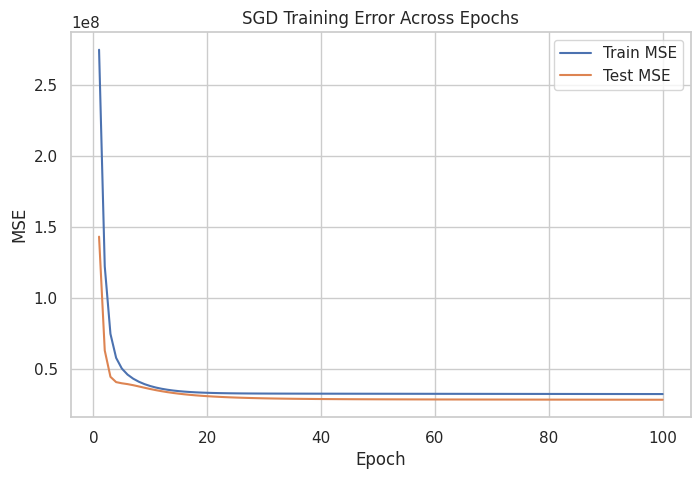

Final coefficients: [ 0.57072606  0.41675588 -0.00933014]
Final intercept: [0.00182535]


In [21]:
X_epoch = data[
    ["YearsExperience", "Age", "EducationLevel"]
]

y_epoch = data["Salary"].to_numpy().reshape(-1, 1)

X_epoch_train, X_epoch_test, y_epoch_train, y_epoch_test = (
    train_test_split(
        X_epoch,
        y_epoch,
        test_size=0.2,
        random_state=12
    )
)

# Scale input features using training data only
x_scaler = StandardScaler()
X_epoch_train_scaled = x_scaler.fit_transform(X_epoch_train)
X_epoch_test_scaled = x_scaler.transform(X_epoch_test)

# Scale the target to make SGD training more stable
y_scaler = StandardScaler()
y_epoch_train_scaled = y_scaler.fit_transform(
    y_epoch_train
).ravel()

sgd_model = SGDRegressor(
    loss="squared_error",
    penalty=None,
    learning_rate="constant",
    eta0=0.01,
    random_state=12
)

epochs = 100
history = []

print("Epoch\tTrain MSE\tTest MSE")

for epoch in range(1, epochs + 1):
    # Each partial_fit call processes one pass over training rows
    sgd_model.partial_fit(
        X_epoch_train_scaled,
        y_epoch_train_scaled
    )

    train_scaled_pred = sgd_model.predict(X_epoch_train_scaled)
    test_scaled_pred = sgd_model.predict(X_epoch_test_scaled)

    # Convert predictions back into salary units
    train_pred = y_scaler.inverse_transform(
        train_scaled_pred.reshape(-1, 1)
    ).ravel()

    test_pred = y_scaler.inverse_transform(
        test_scaled_pred.reshape(-1, 1)
    ).ravel()

    train_mse = mean_squared_error(
        y_epoch_train.ravel(), train_pred
    )

    test_mse = mean_squared_error(
        y_epoch_test.ravel(), test_pred
    )

    history.append({
        "Epoch": epoch,
        "Train MSE": train_mse,
        "Test MSE": test_mse
    })

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"{epoch}\t{train_mse:.2f}\t{test_mse:.2f}"
        )

history_df = pd.DataFrame(history)

plt.figure(figsize=(8, 5))
plt.plot(history_df["Epoch"], history_df["Train MSE"], label="Train MSE")
plt.plot(history_df["Epoch"], history_df["Test MSE"], label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("SGD Training Error Across Epochs")
plt.legend()
plt.show()

print("Final coefficients:", sgd_model.coef_)
print("Final intercept:", sgd_model.intercept_)

In [22]:
classification_df = df[
    ["YearsExperience", "Salary"]
].copy()

median_salary = classification_df["Salary"].median()

classification_df["SalaryCategory"] = np.where(
    classification_df["Salary"] >= median_salary,
    "Higher Salary",
    "Lower Salary"
)

print("Median salary cutoff:", median_salary)
display(classification_df.head())

print("\nCategory counts:")
display(
    classification_df["SalaryCategory"]
    .value_counts()
    .to_frame("Count")
)

Median salary cutoff: 65238.0


,YearsExperience,Salary,SalaryCategory
0,1.2,39344.0,Lower Salary
1,1.4,46206.0,Lower Salary
2,1.6,37732.0,Lower Salary
3,2.1,43526.0,Lower Salary
4,2.3,39892.0,Lower Salary



Category counts:


,Count
SalaryCategory,
Lower Salary,15
Higher Salary,15


In [23]:
from sklearn.pipeline import Pipeline

X_class = classification_df[["YearsExperience"]]
y_class = classification_df["SalaryCategory"]

X_class_train, X_class_test, y_class_train, y_class_test = (
    train_test_split(
        X_class,
        y_class,
        test_size=0.2,
        random_state=42,
        stratify=y_class
    )
)

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_class_train, y_class_train)

class_pred = logistic_model.predict(X_class_test)

print("Accuracy:", accuracy_score(y_class_test, class_pred))
print(
    "Precision:",
    precision_score(
        y_class_test,
        class_pred,
        pos_label="Higher Salary",
        zero_division=0
    )
)
print(
    "Recall:",
    recall_score(
        y_class_test,
        class_pred,
        pos_label="Higher Salary",
        zero_division=0
    )
)
print(
    "F1 Score:",
    f1_score(
        y_class_test,
        class_pred,
        pos_label="Higher Salary",
        zero_division=0
    )
)

print("\nClassification report:")
print(classification_report(y_class_test, class_pred, zero_division=0))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Classification report:
               precision    recall  f1-score   support

Higher Salary       1.00      1.00      1.00         3
 Lower Salary       1.00      1.00      1.00         3

     accuracy                           1.00         6
    macro avg       1.00      1.00      1.00         6
 weighted avg       1.00      1.00      1.00         6



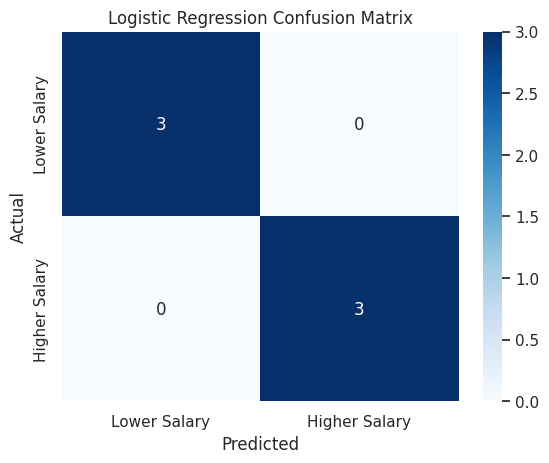

In [24]:
cm = confusion_matrix(
    y_class_test,
    class_pred,
    labels=["Lower Salary", "Higher Salary"]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Lower Salary", "Higher Salary"],
    yticklabels=["Lower Salary", "Higher Salary"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

Decision Tree Accuracy: 1.0

Classification report:
               precision    recall  f1-score   support

Higher Salary       1.00      1.00      1.00         3
 Lower Salary       1.00      1.00      1.00         3

     accuracy                           1.00         6
    macro avg       1.00      1.00      1.00         6
 weighted avg       1.00      1.00      1.00         6



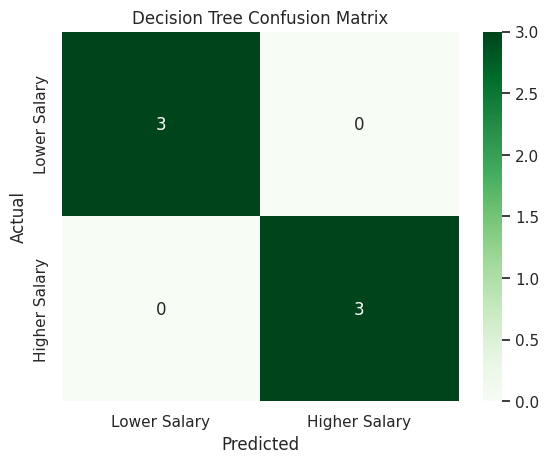

In [25]:
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_model.fit(X_class_train, y_class_train)

tree_pred = tree_model.predict(X_class_test)

print("Decision Tree Accuracy:", accuracy_score(y_class_test, tree_pred))

print("\nClassification report:")
print(classification_report(y_class_test, tree_pred, zero_division=0))

tree_cm = confusion_matrix(
    y_class_test,
    tree_pred,
    labels=["Lower Salary", "Higher Salary"]
)

sns.heatmap(
    tree_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Lower Salary", "Higher Salary"],
    yticklabels=["Lower Salary", "Higher Salary"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [26]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_class_test, class_pred),
        accuracy_score(y_class_test, tree_pred)
    ],
    "F1 Score": [
        f1_score(
            y_class_test, class_pred,
            pos_label="Higher Salary", zero_division=0
        ),
        f1_score(
            y_class_test, tree_pred,
            pos_label="Higher Salary", zero_division=0
        )
    ]
})

display(model_comparison)

,Model,Accuracy,F1 Score
0,Logistic Regression,1.0,1.0
1,Decision Tree,1.0,1.0


In [27]:
models_to_save = {
    "linear_regression.pkl": linear_model,
    "multiple_linear_regression.pkl": multiple_model,
    "logistic_regression.pkl": logistic_model,
    "decision_tree.pkl": tree_model,
    "sgd_regressor.pkl": sgd_model
}

for filename, saved_model in models_to_save.items():
    with open(f"/content/{filename}", "wb") as file:
        pickle.dump(saved_model, file)

print("All models saved successfully!")

for filename in models_to_save:
    print("/content/" + filename)

All models saved successfully!
/content/linear_regression.pkl
/content/multiple_linear_regression.pkl
/content/logistic_regression.pkl
/content/decision_tree.pkl
/content/sgd_regressor.pkl


In [28]:
with open("/content/linear_regression.pkl", "rb") as file:
    loaded_model = pickle.load(file)

test_employee = pd.DataFrame({
    "YearsExperience": [5.0]
})

predicted_salary = loaded_model.predict(test_employee)

print("Experience:", 5.0, "years")
print("Predicted salary:", round(predicted_salary[0], 2))

Experience: 5.0 years
Predicted salary: 71499.28


In [29]:
import zipfile
import os
from google.colab import files

zip_filename = "/content/salary_ml_models.zip"

with zipfile.ZipFile(zip_filename, "w") as zip_file:
    for filename in models_to_save:
        path = f"/content/{filename}"
        if os.path.exists(path):
            zip_file.write(path, arcname=filename)

files.download(zip_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>